# Mərhələ 2: Verilənlərin Ön İşlənməsi

## Məqsədlər

Bu mərhələdə siz:

1. Mərhələ 1-dən təmizlənmiş verilənlər dəstini yükləyəcəksiniz
2. Kateqorial dəyişənləri modellərlə uyğunluq üçün kodlaşdıracaqsınız
3. Say xüsusiyyətlərində əyriliyi (skewness) təhlil edib idarə edəcəksiniz
4. Uyğun miqyaslama (scaling) üsullarını tətbiq edəcəksiniz
5. Ayrı train və test verilənlər dəstlərini hazırlayacaqsınız
6. Xüsusiyyət mühəndisliyi (feature engineering) üçün tam ön işlənmiş verilənlər dəsti yaradacaqsınız

## Təlimatlar

Hər tapşırığı ardıcıllıqla yerinə yetirin. Bu notebook Mərhələ 1-dən gələn təmizlənmiş verilənlər üzərində qurulur.

---
## Tapşırıq 1: Kitabxanaların İdxalı və Təmizlənmiş Verilənlərin Yüklənməsi

In [214]:
# TODO: Lazım olan kitabxanaları idxal edin
# - pandas, numpy, matplotlib.pyplot, seaborn
# - from scipy import stats
# - from sklearn.preprocessing import: LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler

import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import LabelEncoder , OneHotEncoder , StandardScaler , MinMaxScaler , RobustScaler

# TODO: pandas nümayiş parametrlərini təyin edin
# - display.max_columns dəyərini None edin
# - display.max_rows dəyərini 100 edin

pd.set_option('display.max_columns' , None)
pd.set_option('display.max_rows' , 100)

# TODO: Uğur mesajını çap edin
print("uğurla çap edildi")

uğurla çap edildi


In [215]:
# TODO: Mərhələ 1-dən təmizlənmiş verilənləri yükləyin
# - 'train_cleaned.csv' faylını pd.read_csv() ilə oxuyun
# - 'df' dəyişənində saxlayın

df = pd.read_csv("C:/Users/Elton/Desktop/homework house price code star/train_cleaned.csv")

# TODO: Verilənlər dəsti haqqında məlumatı çap edin
# - Verilənlər dəstinin ölçüsü (shape)
# - Çatışmayan dəyərlərin ümumi sayı
# - .head() ilə ilk bir neçə sətri göstərin

df.head()


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,Missing,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,Missing,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,Missing,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,0,12,2008,WD,Normal,250000


In [216]:
df.shape

(1458, 77)

In [217]:
df.isna().sum().sort_values(ascending=False)

Id               0
MSSubClass       0
MSZoning         0
LotFrontage      0
LotArea          0
Street           0
LotShape         0
LandContour      0
Utilities        0
LotConfig        0
LandSlope        0
Neighborhood     0
Condition1       0
Condition2       0
BldgType         0
HouseStyle       0
OverallQual      0
OverallCond      0
YearBuilt        0
YearRemodAdd     0
RoofStyle        0
RoofMatl         0
Exterior1st      0
Exterior2nd      0
MasVnrType       0
MasVnrArea       0
ExterQual        0
ExterCond        0
Foundation       0
BsmtQual         0
BsmtCond         0
BsmtExposure     0
BsmtFinType1     0
BsmtFinSF1       0
BsmtFinType2     0
BsmtFinSF2       0
BsmtUnfSF        0
TotalBsmtSF      0
Heating          0
HeatingQC        0
CentralAir       0
Electrical       0
1stFlrSF         0
2ndFlrSF         0
LowQualFinSF     0
GrLivArea        0
BsmtFullBath     0
BsmtHalfBath     0
FullBath         0
HalfBath         0
BedroomAbvGr     0
KitchenAbvGr     0
KitchenQual 

---
## Tapşırıq 2: Xüsusiyyətlərin və Hədəf Dəyişənin Ayrılması

Ön işləmə üçün hədəf dəyişəni (SalePrice) xüsusiyyətlərdən ayırın.

In [218]:
# TODO: Hədəf dəyişəni xüsusiyyətlərdən ayırın
# - 'y' yaradın = 'SalePrice' sütununun surəti (copy)
# - 'X' yaradın = 'SalePrice' olmadan dataframe

y = df['SalePrice'].copy()
X = df.drop(columns=['SalePrice']).copy()


# TODO: Əgər varsa, X-dən 'Id' sütununu silin (modelləşdirmə üçün faydalı deyil)
# - 'Id' in X.columns yoxlayın
# - Əgər varsa, silin

if "Id" in X.columns:
    X = X.drop(columns=["Id"])

# TODO: Məlumatı çap edin
# - Xüsusiyyətlərin ölçüsü (X.shape)
# - Hədəfin ölçüsü (y.shape)
# - Hədəfin statistikası (y.describe())

print(X.shape)

print(y.shape)

print(y.describe())

(1458, 75)
(1458,)
count      1458.000000
mean     180932.919067
std       79495.055285
min       34900.000000
25%      129925.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


---
## Tapşırıq 3: Kodlaşdırma üçün Xüsusiyyət Tiplərinin Müəyyən Edilməsi

Xüsusiyyətləri kateqoriyalara ayırın və uyğun kodlaşdırma strategiyalarını müəyyən edin.

In [219]:
# TODO: Xüsusiyyət tiplərini müəyyən edin
# - Kateqorial: X.select_dtypes(include=['object']).columns.tolist()
# - Say: X.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

numerical_features = X.select_dtypes(include=["float64" , "int64"]).columns.tolist()

# TODO: Siyahıları say göstəricisi ilə birlikdə çap edin
print("Kateqorial xüsusiyyətlər:", categorical_features)
print("Kateqorial xüsusiyyətlərin sayı:", len(categorical_features))

print("Say xüsusiyyətləri:", numerical_features)
print("Say xüsusiyyətlərinin sayı:", len(numerical_features))

Kateqorial xüsusiyyətlər: ['MSZoning', 'Street', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'SaleType', 'SaleCondition']
Kateqorial xüsusiyyətlərin sayı: 39
Say xüsusiyyətləri: ['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea

C:\Users\Elton\AppData\Local\Temp\ipykernel_22124\3977665753.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object"]).columns.tolist()


In [220]:
# TODO: Kateqorial xüsusiyyətlərin kardinallığını (unikal dəyər sayını) təhlil edin
# - categorical_features üzərində dövr (loop) qurun
# - Hər sütun üçün adı və unikal dəyərlərin sayını çap edin
# - Unikal dəyərləri saymaq üçün .nunique() istifadə edin

for col in categorical_features:
    print(f'sutun adi {col} : unikal deyeri: {X[col].nunique()}')




sutun adi MSZoning : unikal deyeri: 5
sutun adi Street : unikal deyeri: 2
sutun adi LotShape : unikal deyeri: 4
sutun adi LandContour : unikal deyeri: 4
sutun adi Utilities : unikal deyeri: 2
sutun adi LotConfig : unikal deyeri: 5
sutun adi LandSlope : unikal deyeri: 3
sutun adi Neighborhood : unikal deyeri: 25
sutun adi Condition1 : unikal deyeri: 9
sutun adi Condition2 : unikal deyeri: 8
sutun adi BldgType : unikal deyeri: 5
sutun adi HouseStyle : unikal deyeri: 8
sutun adi RoofStyle : unikal deyeri: 6
sutun adi RoofMatl : unikal deyeri: 7
sutun adi Exterior1st : unikal deyeri: 15
sutun adi Exterior2nd : unikal deyeri: 16
sutun adi MasVnrType : unikal deyeri: 4
sutun adi ExterQual : unikal deyeri: 4
sutun adi ExterCond : unikal deyeri: 5
sutun adi Foundation : unikal deyeri: 6
sutun adi BsmtQual : unikal deyeri: 5
sutun adi BsmtCond : unikal deyeri: 5
sutun adi BsmtExposure : unikal deyeri: 5
sutun adi BsmtFinType1 : unikal deyeri: 7
sutun adi BsmtFinType2 : unikal deyeri: 7
sutun ad

---
## Tapşırıq 4: Kateqorial Dəyişənlərin Kodlaşdırılması

### Kodlaşdırma Strategiyası:

1. **Ordinal Xüsusiyyətlər** (təbii sıralaması olan): Label Encoding və ya əl ilə uyğunlaşdırma (manual mapping) istifadə edin
   - Nümunələr: Keyfiyyət qiymətləndirmələri (Ex, Gd, TA, Fa, Po), Vəziyyət qiymətləndirmələri
   
2. **Nominal Xüsusiyyətlər** (təbii sıralaması olmayan): One-Hot Encoding istifadə edin
   - Nümunələr: Neighborhood, Building Type, Exterior Type
   
3. **Yüksək Kardinallıqlı Xüsusiyyətlər** (>10 unikal dəyər): Tezlik kodlaşdırması (frequency encoding) və ya hədəf kodlaşdırması (target encoding) barədə düşünün (irəli səviyyə)

Ordinal xüsusiyyətləri müəyyən etmək üçün `data_description.txt` faylına baxın.

### Addım 4.1: Ordinal və Nominal Xüsusiyyətlərin Müəyyən Edilməsi

Verilənlərin təsvirini nəzərdən keçirin və xüsusiyyətlərinizi kateqoriyalara ayırın.

In [221]:
# TODO: Ordinal xüsusiyyətləri və onların sıralamasını təyin edin
# Ordinal xüsusiyyətləri müəyyən etmək üçün data_description.txt faylına baxın
# Keyfiyyət qiymətləndirmələri üçün ordinal nümunə: Po=1, Fa=2, TA=3, Gd=4, Ex=5
# 
# Aşağıdakıları ehtiva edən ordinal_mappings lüğəti (dictionary) yaradın:
# - Keyfiyyət xüsusiyyətləri (ExterQual, ExterCond və s.)
# - Vəziyyət xüsusiyyətləri
# - Verilənlər lüğətindən digər ordinal xüsusiyyətlər


qual_scale = {"Missing": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
bsmt_fin_scale = {"Missing": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6}


qual_cols = [
    "ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
    "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond"
]

ordinal_mappings = {col: qual_scale for col in qual_cols}

print(ordinal_mappings)

ordinal_mappings.update({
    "GarageFinish": {"Missing": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "PavedDrive":   {"N": 0, "P": 1, "Y": 2},
    "BsmtExposure": {"Missing": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFinType1": bsmt_fin_scale,
    "BsmtFinType2": bsmt_fin_scale,
    "Functional":   {"Sal": 1, "Sev": 2, "Maj2": 3, "Maj1": 4,
                    "Mod": 5, "Min2": 6, "Min1": 7, "Typ": 8},
})


print(ordinal_mappings)

ordinal_features = list(ordinal_mappings.keys())
nominal_features = [col for col in categorical_features if col not in ordinal_features]



# TODO: Xüsusiyyətləri ordinal və nominal olaraq ayırın
# - ordinal_features: ordinal xüsusiyyət adlarının siyahısı
# - nominal_features: ordinal siyahıda olmayan kateqorial xüsusiyyətlər


print("Ordinal sayı:", len(ordinal_features))
print(ordinal_features)
print("\nNominal sayı:", len(nominal_features))
print(nominal_features)

# TODO: Ordinal və nominal xüsusiyyətlərin sayını və adlarını çap edin


{'ExterQual': {'Missing': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}, 'ExterCond': {'Missing': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}, 'BsmtQual': {'Missing': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}, 'BsmtCond': {'Missing': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}, 'HeatingQC': {'Missing': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}, 'KitchenQual': {'Missing': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}, 'FireplaceQu': {'Missing': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}, 'GarageQual': {'Missing': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}, 'GarageCond': {'Missing': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}}
{'ExterQual': {'Missing': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}, 'ExterCond': {'Missing': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}, 'BsmtQual': {'Missing': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}, 'BsmtCond': {'Missing': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}, 'HeatingQC': {'Missing': 0, 'Po': 

### Addım 4.2: Ordinal Kodlaşdırmanın Tətbiqi

In [222]:
# TODO: Kodlaşdırma üçün surət yaradın
# X_encoded = X.copy()

X_encoded = X.copy()


# TODO: Ordinal kodlaşdırmanı tətbiq edin
# - ordinal_mappings üzərində dövr qurun
# - Hər xüsusiyyəti .map() metodu ilə uyğunlaşdırın
# - Hər kodlaşdırılmış xüsusiyyət üçün təsdiq mesajı çap edin

for col , mapping in ordinal_mappings.items():
    if col in X_encoded.columns:
        X_encoded[col] = X_encoded[col].map(mapping)
        print(f"{col} kodlaşdırıldı.")

# TODO: Kodlaşdırmanı yoxlayın
# - Uyğunlaşdırmanın düzgün işlədiyini yoxlamaq üçün ordinal xüsusiyyətlərin ilk sətirlərini göstərin

nan_check = X_encoded[ordinal_features].isna().sum()
print("\nNaN yaranan sütunlar (boş olmalıdır):")

print(nan_check[nan_check > 0])

X_encoded[ordinal_features].head()

ExterQual kodlaşdırıldı.
ExterCond kodlaşdırıldı.
BsmtQual kodlaşdırıldı.
BsmtCond kodlaşdırıldı.
HeatingQC kodlaşdırıldı.
KitchenQual kodlaşdırıldı.
FireplaceQu kodlaşdırıldı.
GarageQual kodlaşdırıldı.
GarageCond kodlaşdırıldı.
GarageFinish kodlaşdırıldı.
PavedDrive kodlaşdırıldı.
BsmtExposure kodlaşdırıldı.
BsmtFinType1 kodlaşdırıldı.
BsmtFinType2 kodlaşdırıldı.
Functional kodlaşdırıldı.

NaN yaranan sütunlar (boş olmalıdır):
Series([], dtype: int64)


,ExterQual,ExterCond,BsmtQual,BsmtCond,HeatingQC,KitchenQual,FireplaceQu,GarageQual,GarageCond,GarageFinish,PavedDrive,BsmtExposure,BsmtFinType1,BsmtFinType2,Functional
0,4,3,4,3,5,4,0,3,3,2,2,1,6,1,8
1,3,3,4,3,5,3,3,3,3,2,2,4,5,1,8
2,4,3,4,3,5,4,3,3,3,2,2,2,6,1,8
3,3,3,3,4,4,4,4,3,3,1,2,1,5,1,8
4,4,3,4,3,5,4,3,3,3,2,2,3,6,1,8


### Addım 4.3: Nominal Xüsusiyyətlərə One-Hot Kodlaşdırmanın Tətbiqi

In [223]:
# TODO: Nominal xüsusiyyətlərə one-hot kodlaşdırma tətbiq edin
# - nominal_features siyahısının boş olmadığını yoxlayın
# - pd.get_dummies() funksiyasını aşağıdakılarla istifadə edin:
#   * columns=nominal_features
#   * drop_first=True (multikollinearlıqdan qaçmaq üçün)
# - Yeni ölçünü və xüsusiyyət sayını çap edin

if nominal_features:
    X_encoded = pd.get_dummies(X_encoded , columns=nominal_features, drop_first=True)


    print(X.shape)
    print("Yeni ölçü:", X_encoded.shape)
    print("Xüsusiyyət sayı:", X_encoded.shape[1])

(1458, 75)
Yeni ölçü: (1458, 196)
Xüsusiyyət sayı: 196


In [224]:
# TODO: Kodlaşdırılmış verilənlər dəstindən nümunə göstərin
# - Mesaj çap edin
# - X_encoded-in ilk bir neçə sətrini göstərin

X_encoded.head()


,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,ExterQual,ExterCond,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,HeatingQC,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,MSZoning_FV,MSZoning_RH,MSZoning_RL,MSZoning_RM,Street_Pave,LotShape_IR2,LotShape_IR3,LotShape_Reg,LandContour_HLS,LandContour_Low,LandContour_Lvl,Utilities_NoSeWa,LotConfig_CulDSac,LotConfig_FR2,LotConfig_FR3,LotConfig_Inside,LandSlope_Mod,LandSlope_Sev,Neighborhood_Blueste,Neighborhood_BrDale,Neighborhood_BrkSide,Neighborhood_ClearCr,Neighborhood_CollgCr,Neighborhood_Crawfor,Neighborhood_Edwards,Neighborhood_Gilbert,Neighborhood_IDOTRR,Neighborhood_MeadowV,Neighborhood_Mitchel,Neighborhood_NAmes,Neighborhood_NPkVill,Neighborhood_NWAmes,Neighborhood_NoRidge,Neighborhood_NridgHt,Neighborhood_OldTown,Neighborhood_SWISU,Neighborhood_Sawyer,Neighborhood_SawyerW,Neighborhood_Somerst,Neighborhood_StoneBr,Neighborhood_Timber,Neighborhood_Veenker,Condition1_Feedr,Condition1_Norm,Condition1_PosA,Condition1_PosN,Condition1_RRAe,Condition1_RRAn,Condition1_RRNe,Condition1_RRNn,Condition2_Feedr,Condition2_Norm,Condition2_PosA,Condition2_PosN,Condition2_RRAe,Condition2_RRAn,Condition2_RRNn,BldgType_2fmCon,BldgType_Duplex,BldgType_Twnhs,BldgType_TwnhsE,HouseStyle_1.5Unf,HouseStyle_1Story,HouseStyle_2.5Fin,HouseStyle_2.5Unf,HouseStyle_2Story,HouseStyle_SFoyer,HouseStyle_SLvl,RoofStyle_Gable,RoofStyle_Gambrel,RoofStyle_Hip,RoofStyle_Mansard,RoofStyle_Shed,RoofMatl_Membran,RoofMatl_Metal,RoofMatl_Roll,RoofMatl_Tar&Grv,RoofMatl_WdShake,RoofMatl_WdShngl,Exterior1st_AsphShn,Exterior1st_BrkComm,Exterior1st_BrkFace,Exterior1st_CBlock,Exterior1st_CemntBd,Exterior1st_HdBoard,Exterior1st_ImStucc,Exterior1st_MetalSd,Exterior1st_Plywood,Exterior1st_Stone,Exterior1st_Stucco,Exterior1st_VinylSd,Exterior1st_Wd Sdng,Exterior1st_WdShing,Exterior2nd_AsphShn,Exterior2nd_Brk Cmn,Exterior2nd_BrkFace,Exterior2nd_CBlock,Exterior2nd_CmentBd,Exterior2nd_HdBoard,Exterior2nd_ImStucc,Exterior2nd_MetalSd,Exterior2nd_Other,Exterior2nd_Plywood,Exterior2nd_Stone,Exterior2nd_Stucco,Exterior2nd_VinylSd,Exterior2nd_Wd Sdng,Exterior2nd_Wd Shng,MasVnrType_BrkFace,MasVnrType_Missing,MasVnrType_Stone,Foundation_CBlock,Foundation_PConc,Foundation_Slab,Foundation_Stone,Foundation_Wood,Heating_GasA,Heating_GasW,Heating_Grav,Heating_OthW,Heating_Wall,CentralAir_Y,Electrical_FuseF,Electrical_FuseP,Electrical_Mix,Electrical_SBrkr,GarageType_Attchd,GarageType_Basment,GarageType_BuiltIn,GarageType_CarPort,GarageType_Detchd,GarageType_Missing,SaleType_CWD,SaleType_Con,SaleType_ConLD,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,60,65.0,8450,7,5,2003,2003,196.0,4,3,4,3,1,6,706,1,0,150,856,5,856,854,0,1710,1,0,2,1,3,1,4,8,8,0,0,2003.0,2,2,548,3,3,2,0,61,0,0,0,0,0,2,2008,False,False,True,False,True,False,False,True,False,False,True,False,False,False,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,True,False,False,False,True,False,False,False,False,True,False,False,False,True,True,False,False,

---
## Tapşırıq 5: Paylanmanın və Əyriliyin Təhlili

Say xüsusiyyətlərinin paylanmasını araşdırın və yüksək əyriliyə malik xüsusiyyətləri müəyyən edin.

In [225]:
# TODO: Bütün say xüsusiyyətləri üçün əyriliyi (skewness) hesablayın
# - select_dtypes ilə say sütunlarını seçin
# - Hər sütuna stats.skew() tətbiq edin
# - Feature və Skewness sütunlarından ibarət DataFrame yaradın
# - Mütləq əyriliyə görə azalan sıra ilə düzün
# - Ən çox əyriliyə malik 20 xüsusiyyəti çap edin

skew_data = []

for col in numerical_features:
    skew_value = stats.skew(X_encoded[col])
    skew_data.append({
        "Feature" : col ,
        "Skewness" : skew_value
    })



skew_df = pd.DataFrame(skew_data)

skew_df["Abs_skewness"] = skew_df["Skewness"].abs()
skew_df = skew_df.sort_values("Abs_skewness", ascending=False)

print(skew_df[["Feature", "Skewness"]].head(20))

# TODO: Yüksək əyriliyə malik xüsusiyyətləri müəyyən edin
# - |skewness| > 0.75 olan xüsusiyyətləri süzün
# - highly_skewed siyahısında saxlayın
# - Yüksək əyriliyə malik xüsusiyyətlərin sayını və siyahısını çap edin


          Feature   Skewness
33        MiscVal  24.434913
32       PoolArea  15.932532
2         LotArea  12.560986
30      3SsnPorch  10.286510
14   LowQualFinSF   8.995688
21   KitchenAbvGr   4.480268
9      BsmtFinSF2   4.247550
31    ScreenPorch   4.114690
17   BsmtHalfBath   4.095895
24    GarageYrBlt  -3.862401
29  EnclosedPorch   3.083987
7      MasVnrArea   2.693554
28    OpenPorchSF   2.337421
1     LotFrontage   1.719086
27     WoodDeckSF   1.544214
0      MSSubClass   1.405563
15      GrLivArea   1.009951
10      BsmtUnfSF   0.919955
12       1stFlrSF   0.886723
13       2ndFlrSF   0.812121


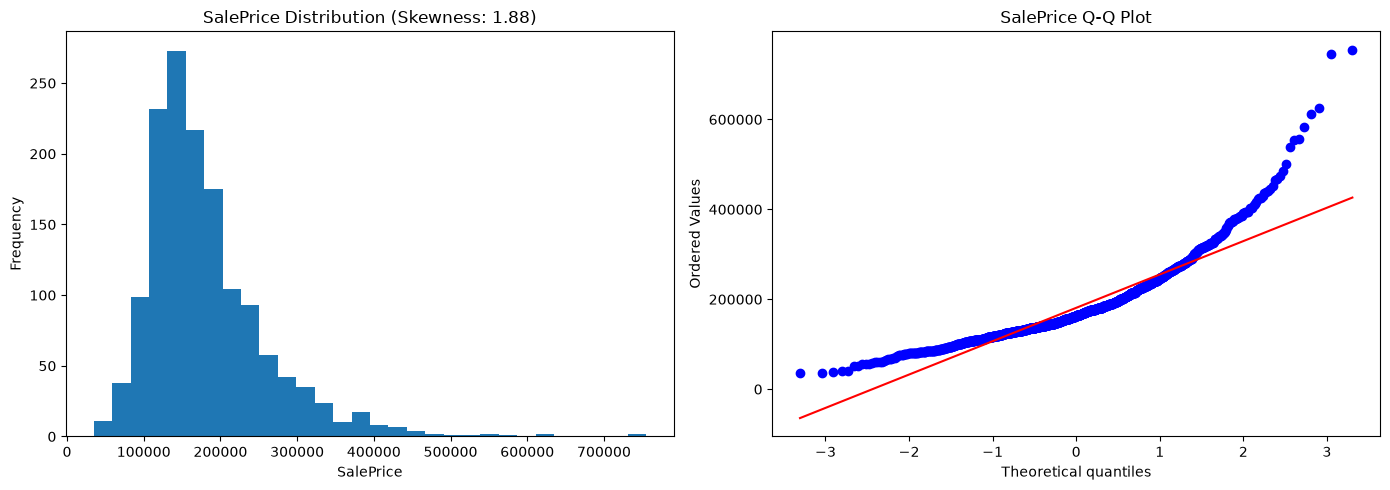

In [226]:
# TODO: Hədəf dəyişənin paylanmasını vizuallaşdırın
# - 1x2 subplot fiquru yaradın (figsize=(14, 5))
# - Sol qrafik: Başlıqda əyriliyi göstərməklə SalePrice histoqramı
# - Sağ qrafik: stats.probplot() ilə Q-Q qrafiki
# - Qrafikləri göstərin

skewness = stats.skew(y)

fig , axes = plt.subplots(1 , 2 , figsize = (14,5))
axes[0].hist(y , bins=30)
axes[0].set_title(f"SalePrice Distribution (Skewness: {skewness:.2f})")
axes[0].set_xlabel("SalePrice")
axes[0].set_ylabel("Frequency")


# TODO: Hədəf dəyişənin əyriliyini çap edin
stats.probplot(y , dist='norm' , plot=axes[1])
axes[1].set_title("SalePrice Q-Q Plot")

plt.tight_layout()
plt.show()

---
## Tapşırıq 6: Əyriliyin İdarə Edilməsi

Yüksək əyriliyə malik xüsusiyyətlərdə əyriliyi azaltmaq üçün transformasiyalar tətbiq edin.

**Ümumi transformasiyalar:**
- Loqarifmik transformasiya: `log1p(x)` - sağa əyri verilənlər üçün yaxşıdır
- Kvadrat kök: `sqrt(x)` - orta dərəcəli sağa əyrilik üçün
- Box-Cox: Avtomatik optimal transformasiya (müsbət dəyərlər tələb edir)

**Nə vaxt tətbiq etməli:**
- Sağa əyri (müsbət əyrilik > 0.75): Loqarifmik transformasiyadan istifadə edin
- Sola əyri (mənfi əyrilik < -0.75): Əksetdirmə (reflection) + loqarifm barədə düşünün

### Addım 6.1: Hədəf Dəyişənin Transformasiyası

Əgər hədəf dəyişən əyridirsə, modelin daha yaxşı performansı üçün onu transformasiya edin.

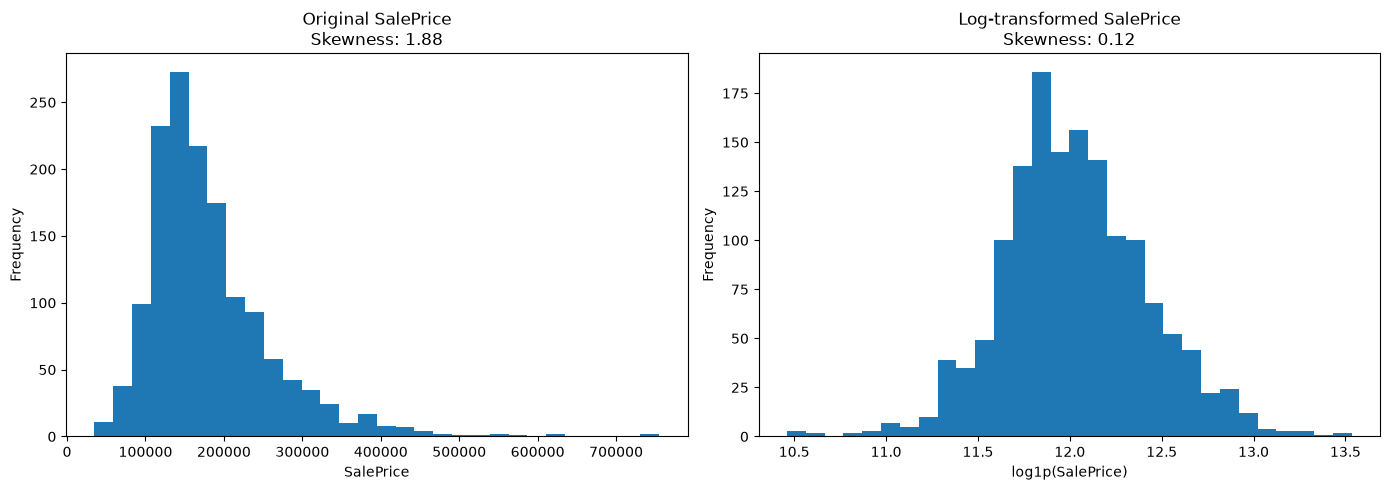

In [227]:
# TODO: Hədəfin transformasiyaya ehtiyacı olub-olmadığını yoxlayın
# - Hədəfin əyriliyini hesablayın
# - Əgər |skewness| > 0.75 isə:
#   * np.log1p() ilə loqarifmik transformasiya tətbiq edin
#   * Yeni əyriliyi hesablayın
#   * Orijinal və transformasiya olunmuşu müqayisə edən yan-yana qrafiklər yaradın
#   * Əyriliyin əvvəlki və sonrakı dəyərlərini çap edin
# - Əks halda: Orijinal hədəfi saxlayın və mesaj çap edin


target_skewness = stats.skew(y)

if abs(target_skewness) > 0.75:
    y_log = np.log1p(y)

    transformed_skewness = stats.skew(y_log)

    fig , axes = plt.subplots(1 , 2 , figsize= (14, 5))

    # Original target
    axes[0].hist(y, bins=30)
    axes[0].set_title(f"Original SalePrice\nSkewness: {target_skewness:.2f}")
    axes[0].set_xlabel("SalePrice")
    axes[0].set_ylabel("Frequency")
    
    # Transformasiya olunmuş target
    axes[1].hist(y_log, bins=30)
    axes[1].set_title(f"Log-transformed SalePrice\nSkewness: {transformed_skewness:.2f}")
    axes[1].set_xlabel("log1p(SalePrice)")
    axes[1].set_ylabel("Frequency")
    
    plt.tight_layout()
    plt.show()
else :
    y_log = y.copy()
    print(f"Target transformasiyaya ehtiyac duymur.")
    print(f"Skewness: {target_skewness:.4f}")




### Addım 6.2: Yüksək Əyriliyə Malik Xüsusiyyətlərin Transformasiyası

In [228]:
# TODO: Yüksək əyriliyə malik xüsusiyyətlərə loqarifmik transformasiya tətbiq edin
# - X_encoded-in surətini X_transformed kimi yaradın
# - highly_skewed xüsusiyyətləri üzərində dövr qurun:
#   * Bütün dəyərlərin qeyri-mənfi olduğunu yoxlayın
#   * np.log1p() transformasiyasını tətbiq edin
#   * Hər xüsusiyyət üçün əyriliyin əvvəlki və sonrakı dəyərlərini çap edin
# - Tamamlanma mesajı çap edin

X_transformed = X_encoded.copy()
highly_skewed = skew_df[skew_df["Skewness"].abs() > 0.75]["Feature"].tolist()

print(highly_skewed)

for col in highly_skewed:

    if (X_transformed[col] >= 0).all():

        before = stats.skew(X_transformed[col])

        X_transformed[col] = np.log1p(X_transformed[col])

        after = stats.skew(X_transformed[col])

        print(f"{col}: {before:.4f} → {after:.4f}")
        
    else:
        print(f"{col}: Mənfi dəyərlər var, transformasiya edilmədi.")

print("\nLog transformasiya tamamlandı.")

['MiscVal', 'PoolArea', 'LotArea', '3SsnPorch', 'LowQualFinSF', 'KitchenAbvGr', 'BsmtFinSF2', 'ScreenPorch', 'BsmtHalfBath', 'GarageYrBlt', 'EnclosedPorch', 'MasVnrArea', 'OpenPorchSF', 'LotFrontage', 'WoodDeckSF', 'MSSubClass', 'GrLivArea', 'BsmtUnfSF', '1stFlrSF', '2ndFlrSF', 'BsmtFinSF1']
MiscVal: 24.4349 → 5.1615
PoolArea: 15.9325 → 15.5017
LotArea: 12.5610 → -0.1811
3SsnPorch: 10.2865 → 7.7215
LowQualFinSF: 8.9957 → 7.4473
KitchenAbvGr: 4.4803 → 3.8623
BsmtFinSF2: 4.2475 → 2.5186
ScreenPorch: 4.1147 → 3.1444
BsmtHalfBath: 4.0959 → 3.9258
GarageYrBlt: -3.8624 → -3.8802
EnclosedPorch: 3.0840 → 2.1078
MasVnrArea: 2.6936 → 0.5058
OpenPorchSF: 2.3374 → -0.0229
LotFrontage: 1.7191 → -0.9686
WoodDeckSF: 1.5442 → 0.1564
MSSubClass: 1.4056 → 0.2503
GrLivArea: 1.0100 → -0.0709
BsmtUnfSF: 0.9200 → -2.1821
1stFlrSF: 0.8867 → 0.0070
2ndFlrSF: 0.8121 → 0.2925
BsmtFinSF1: 0.7640 → -0.6175

Log transformasiya tamamlandı.


---
## Tapşırıq 7: Xüsusiyyətlərin Miqyaslanması (Feature Scaling)

Say xüsusiyyətlərinə uyğun miqyaslama tətbiq edin.

**Miqyaslama üsulları:**
1. **StandardScaler**: Orta=0, Standart sapma=1 (normal paylanmış verilənlər üçün yaxşıdır)
2. **MinMaxScaler**: [0,1] aralığına miqyaslayır (məhdud paylanmalar üçün yaxşıdır)
3. **RobustScaler**: Median və IQR istifadə edir (kənar qiymətlərə qarşı davamlıdır)

**Nə vaxt istifadə etməli:**
- StandardScaler: Ən geniş yayılmışdır, əyriliyin düzəldilməsindən sonra yaxşı işləyir
- RobustScaler: Kənar qiymətlər (outliers) mövcud və vacib olduqda
- MinMaxScaler: Xüsusiyyət aralığı vacib olduqda (məsələn, neyron şəbəkələri)

In [229]:
# TODO: Transformasiyadan sonra say sütunlarını əldə edin
# - X_transformed-dən say sütunlarını seçin
# - numeric_features siyahısında saxlayın
# - Miqyaslanacaq xüsusiyyətlərin sayını çap edin

numeric_features  = X_transformed.select_dtypes(include=['float64' , 'int64']).columns.tolist()
print(f"Miqyaslanacaq numerical feature sayı: {len(numeric_features)}")
print(numeric_features)


Miqyaslanacaq numerical feature sayı: 51
['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'HeatingQC', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']


### Addım 7.1: Miqyaslama Üsulunun Seçilməsi və Tətbiqi

Bir miqyaslama üsulu seçin və onu say xüsusiyyətlərinə tətbiq edin.

In [230]:
# TODO: Miqyaslama üçün surət yaradın
# X_scaled = X_transformed.copy()

X_scaled  = X_transformed.copy()
# TODO: Miqyaslama üsulunu seçin və başladın (initialize)
# - StandardScaler() - loqarifmik transformasiyadan sonra tövsiyə olunur
# - RobustScaler() - kənar qiymətlər vacibdirsə alternativdir
# - MinMaxScaler() - məhdud aralıq üçün alternativdir


scaler = StandardScaler()

X_scaled[numerical_features] = scaler.fit_transform(X_scaled[numerical_features])


# TODO: Say xüsusiyyətlərinə miqyaslamanı tətbiq edin
# - numeric_features üzərində fit_transform() istifadə edin
# - Miqyaslayıcının adını və miqyaslanmış statistikanı çap edin


print(f"Scaler: {scaler.__class__.__name__}")
print("\nMiqyaslanmış statistika:")

print(X_scaled[numeric_features].describe().loc[["mean", "std"]])


Scaler: StandardScaler

Miqyaslanmış statistika:
        MSSubClass   LotFrontage       LotArea   OverallQual   OverallCond  \
mean -1.589949e-16  3.474739e-15 -1.386484e-15 -2.850943e-16  3.204265e-16   
std   1.000343e+00  1.000343e+00  1.000343e+00  1.000343e+00  1.000343e+00   

         YearBuilt  YearRemodAdd    MasVnrArea  ExterQual  ExterCond  \
mean  3.033696e-15  3.323664e-15  7.066440e-17   3.393690   3.083676   
std   1.000343e+00  1.000343e+00  1.000343e+00   0.571589   0.351281   

      BsmtQual  BsmtCond  BsmtExposure  BsmtFinType1    BsmtFinSF1  \
mean  3.486968  2.934842      1.626886      3.542524 -9.259473e-17   
std   0.875289  0.552532      1.064504      2.107258  1.000343e+00   

      BsmtFinType2    BsmtFinSF2     BsmtUnfSF   TotalBsmtSF  HeatingQC  \
mean      1.247599  4.386066e-17  7.894919e-16  2.144299e-16   4.144033   
std       0.892898  1.000343e+00  1.000343e+00  1.000343e+00   0.959636   

          1stFlrSF      2ndFlrSF  LowQualFinSF     GrLivArea  

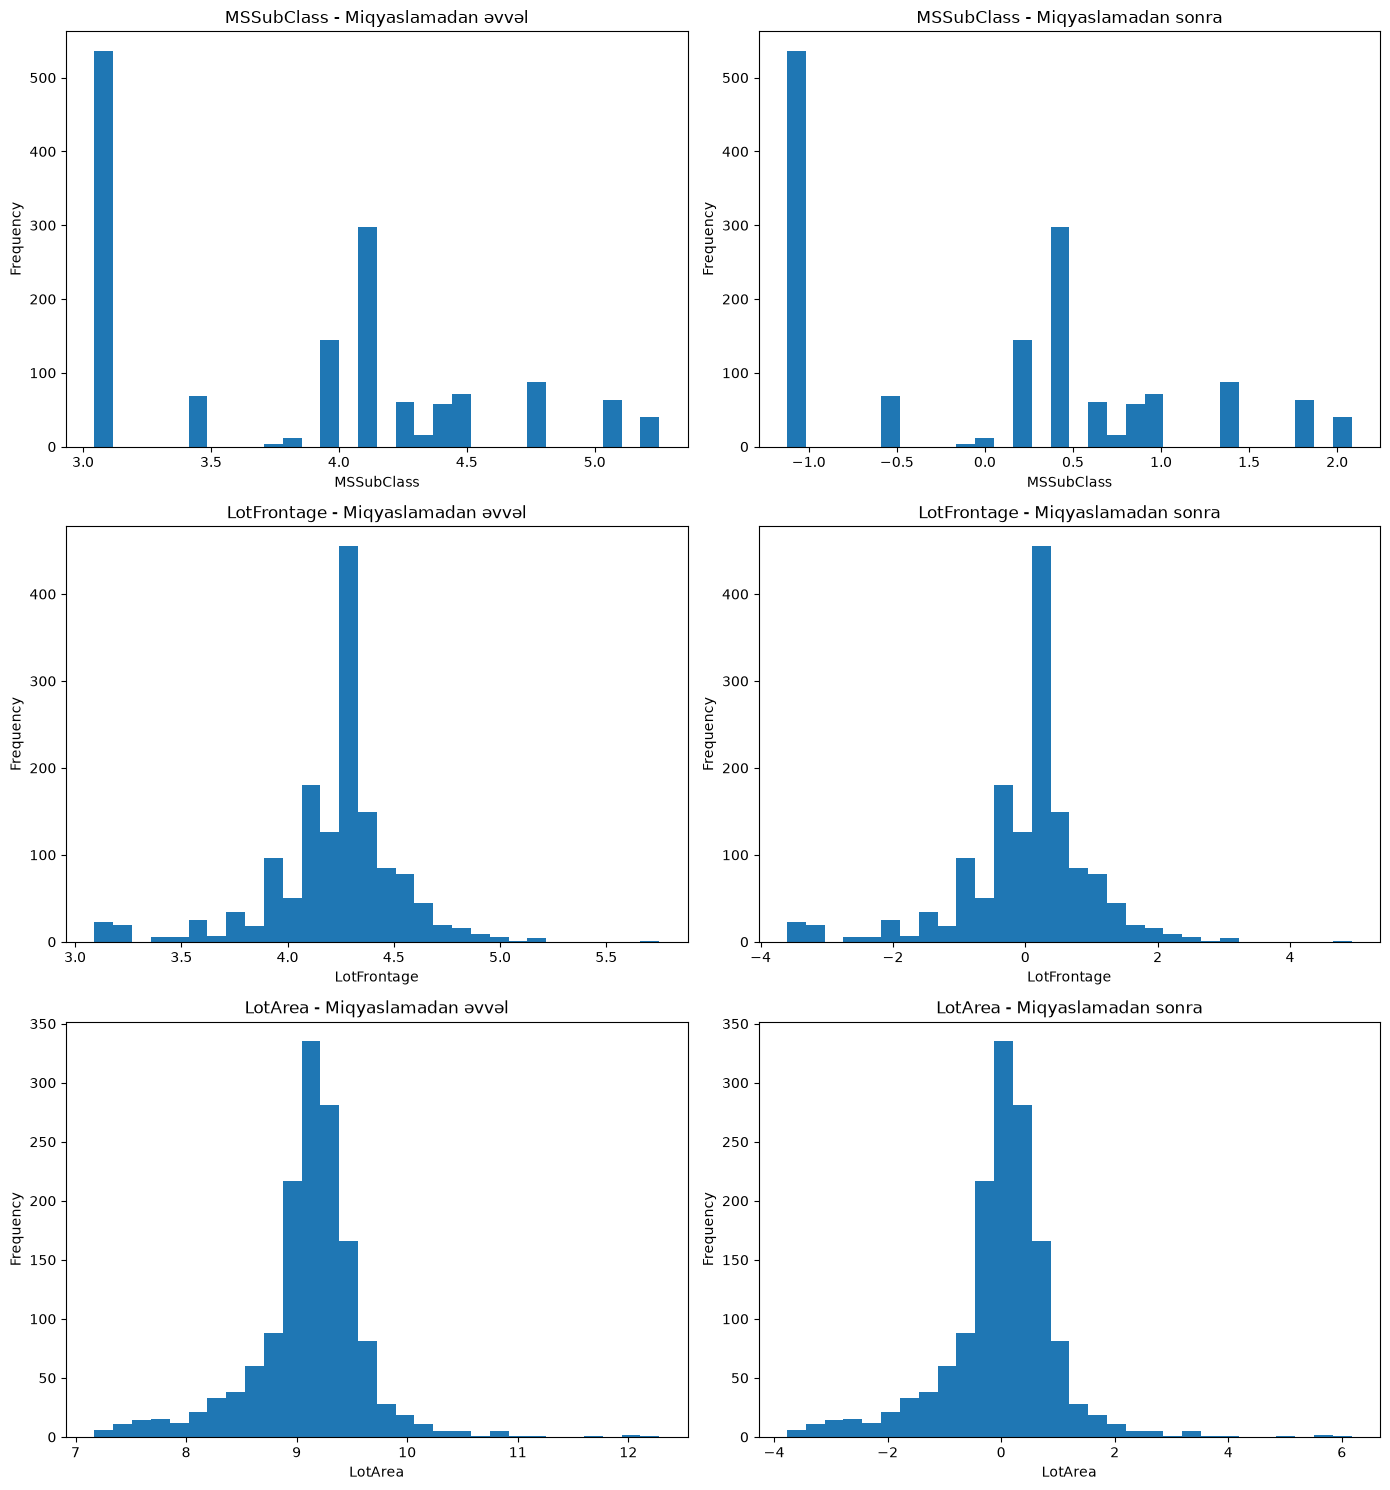

In [231]:
# TODO: Miqyaslamanın təsirini vizuallaşdırın
# - Nümunə olaraq ilk 3 say xüsusiyyətini seçin
# - Subplot-lar yaradın (sətir sayı = xüsusiyyətlərin sayı, sütun sayı = 2)
# - Hər xüsusiyyət üçün:
#   * Sol: miqyaslamadan əvvəl histoqram
#   * Sağ: miqyaslamadan sonra histoqram
# - Müqayisə qrafiklərini göstərin

sample_features = numerical_features[:3]

fig, axes = plt.subplots(
    nrows=len(sample_features),
    ncols=2,
    figsize=(14, 5 * len(sample_features))
)

for i , col in enumerate(sample_features):

    axes[i ,0].hist(X_transformed[col] , bins = 30)
    axes[i, 0].set_title(f"{col} - Miqyaslamadan əvvəl")
    axes[i, 0].set_xlabel(col)
    axes[i, 0].set_ylabel("Frequency")

    axes[i, 1].hist(X_scaled[col], bins=30)
    axes[i, 1].set_title(f"{col} - Miqyaslamadan sonra")
    axes[i, 1].set_xlabel(col)
    axes[i, 1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


---
## Tapşırıq 8: Test Verilənlər Dəstinin İşlənməsi

Eyni ön işləmə addımlarını test verilənlər dəstinə tətbiq edin.

**Vacib:** Train dəstindən eyni transformasiyaları və miqyaslama parametrlərini istifadə edin.

In [232]:
# TODO: Test verilənlər dəstini yükləyin
# - 'test.csv' faylını oxuyun
# - Ölçünü və çatışmayan dəyərlərin sayını çap edin

test_df = pd.read_csv("test.csv")

print("Test dataset ölçüsü:", test_df.shape)
print("Missing values:", test_df.isna().sum().sum())

# TODO: Sonradan təqdimat (submission) üçün test ID-lərini saxlayın
# - 'Id' sütununu çıxarın və saxlayın

test_ids = test_df['Id'].copy()

test_df = test_df.drop(columns=["Id"])

# TODO: test_df-dən 'Id' sütununu silin

print("Test datasetinin yeni ölçüsü:", test_df.shape)



Test dataset ölçüsü: (1459, 80)
Missing values: 7878
Test datasetinin yeni ölçüsü: (1459, 79)


### Addım 8.1: Test Verilənlərinə Eyni Təmizləmə və Kodlaşdırmanın Tətbiqi

Mərhələ 1-dəki təmizləmə addımlarını və bu notebook-dakı kodlaşdırmanı təkrarlayın.

**Əsas nüanslar:**
- Çatışmayan dəyərləri eyni strategiya ilə idarə edin
- Eyni xüsusiyyətləri silin
- Eyni kodlaşdırma uyğunlaşdırmalarından (mappings) istifadə edin

In [ ]:
# TODO: Test verilənlərinə eyni ön işləmə addımlarını tətbiq edin
# KRİTİK: Train verilənlərindəki ilə eyni transformasiyaları istifadə edin
# 
# Təkrarlanacaq addımlar:
# 1. Çatışmayan dəyərləri idarə edin (train ilə eyni strategiya)

features_to_drop = ['PoolQC', 'MiscFeature', 'Alley', 'Fence']

none_features = [
    'MasVnrType', 'BsmtQual', 'BsmtCond', 'BsmtExposure',
    'BsmtFinType1', 'BsmtFinType2', 'FireplaceQu',
    'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
]


zero_features = ['GarageYrBlt', 'MasVnrArea',
                'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
                'BsmtFullBath', 'BsmtHalfBath', 'GarageCars', 'GarageArea']

mode_features = ['MSZoning', 'Utilities', 'Exterior1st', 'Exterior2nd',
                'KitchenQual', 'Functional', 'SaleType', 'Electrical']

test_clean = test_df.drop(columns=features_to_drop).copy()

for col in none_features:
    test_clean[col] = test_clean[col].fillna("Missing")

test_clean[zero_features] = test_clean[zero_features].fillna(0)

for col in mode_features:
    test_clean[col] = test_clean[col].fillna(X[col].mode()[0])

test_clean["LotFrontage"] = test_clean['LotFrontage'].fillna(X['LotFrontage'].median())

test_clean.duplicated().sum().sum()

# 2. Eyni xüsusiyyətləri silin
test_encoded = test_clean.copy()

for col , mapping in ordinal_mappings.items():
    test_encoded[col] = test_encoded[col].map(mapping)

nan_check = test_encoded[ordinal_features].isna().sum()
print("Ordinal NaN (boş olmalıdır):")
print(nan_check[nan_check > 0])

# 3. Eyni ordinal kodlaşdırmanı tətbiq edin (eyni mappings istifadə edin)
# 4. Eyni one-hot kodlaşdırmanı tətbiq edin (eyni sütunlar)

test_encoded = pd.get_dummies(test_encoded , columns=nominal_features)
test_encoded = test_encoded.reindex(columns=X_encoded.columns , fill_value=0)

# 5. Eyni transformasiyaları tətbiq edin (eyni xüsusiyyətlərə log transformasiya)
# 6. Eyni miqyaslamanı tətbiq edin (scaler.transform() istifadə edin, fit_transform() YOX)

log_cols = [col for col in highly_skewed if (X_encoded[col] > 0).all()]
test_transformed = test_encoded.copy()
test_transformed[log_cols] = np.log1p(test_transformed[log_cols])

test_scaled = test_transformed.copy()
test_scaled[numerical_features] = scaler.transform(test_scaled[numerical_features])

# Sizin implementasiyanız burada

print("\nTest shape:", test_scaled.shape, "| Train shape:", X_scaled.shape)
print("Qalan NaN:", test_scaled.isna().sum().sum())
print("Sütunlar və sıra train ilə eynidir:", list(test_scaled.columns) == list(X_scaled.columns))




Ordinal NaN (boş olmalıdır):
Series([], dtype: int64)

Test shape: (1459, 196) | Train shape: (1458, 196)
Qalan NaN: 0
Sütunlar və sıra train ilə eynidir: True


---
## Tapşırıq 9: Yekun Yoxlama və Yadda Saxlama

Ön işləmənin tamamlandığını yoxlayın və verilənlər dəstlərini yadda saxlayın.

In [ ]:
# TODO: Yekun yoxlama - Xülasə statistikasını çap edin
# Train Dəsti:
#   - Ölçü (shape)
#   - Çatışmayan dəyərlərin sayı
#   - Verilənlər tiplərinin paylanması

print("=== Train dəsti ===")
print("Shape:", X_scaled.shape)
print("Çatışmayan dəyərlərin sayı:", X_scaled.isna().sum().sum())
print("Data tiplərinin paylanması:")
print(X_scaled.dtypes.value_counts())

# 
# Hədəf Dəyişən:
#   - Ölçü (shape)
#   - Aralıq (min, max)
#   - Əyrilik (skewness)

print("\n=== Hədəf dəyişən (log1p) ===")
print("Shape:", y_log.shape)
print("Min:", y_log.min(), "| Max:", y_log.max())
print("Skewness:", stats.skew(y_log))

non_numeric = X_scaled.select_dtypes(exclude=["number", "bool"]).columns.tolist()
print("\nSay olmayan sütunlar (boş olmalıdır):", non_numeric)

#
# TODO: Bütün xüsusiyyətlərin say tipində olduğunu yoxlayın (heç bir object tipi qalmamalıdır)


=== Train dəsti ===
Shape: (1458, 196)
Çatışmayan dəyərlərin sayı: 0
Data tiplərinin paylanması:
bool       145
float64     36
int64       15
Name: count, dtype: int64

=== Hədəf dəyişən (log1p) ===
Shape: (1458,)
Min: 10.460270761075149 | Max: 13.534474352733596
Skewness: 0.12145464268184532

Say olmayan sütunlar (boş olmalıdır): []


In [235]:
# TODO: Ön işlənmiş verilənlər dəstlərini yadda saxlayın
# - X_scaled-i 'train_preprocessed.csv' faylına yazın (index=False)
# - y_transformed-i 'SalePrice' sütunu olan DataFrame kimi 'train_target.csv' faylına yazın
# - Fayl adları ilə təsdiq mesajlarını çap edin

X_scaled.to_csv("train_preprocessed.csv", index=False)
print("train_preprocessed.csv saxlanıldı:", X_scaled.shape)

y_transformed = y_log.copy()
pd.DataFrame({"SalePrice": y_transformed}).to_csv("train_target.csv", index=False)
print("train_target.csv saxlanıldı:", y_transformed.shape)

train_preprocessed.csv saxlanıldı: (1458, 196)
train_target.csv saxlanıldı: (1458,)


---
## Xülasə və Refleksiya

### Nələr Əldə Etdiniz:

1. Mərhələ 1-dən təmizlənmiş verilənləri yüklədiniz
2. Xüsusiyyətləri və hədəf dəyişəni ayırdınız
3. Kateqorial dəyişənləri kodlaşdırdınız (ordinal və one-hot kodlaşdırma)
4. Say xüsusiyyətlərində əyriliyi təhlil edib azaltdınız
5. Say xüsusiyyətlərinə uyğun miqyaslama tətbiq etdiniz
6. Test verilənlər dəstini eyni transformasiyalarla ön işlədiniz
7. Modelə hazır verilənlər dəstləri yaratdınız

### Refleksiya üçün Əsas Suallar:

1. One-hot kodlaşdırmadan sonra neçə xüsusiyyətiniz var?
2. Ordinal xüsusiyyətlər üçün hansı kodlaşdırma üsulunu istifadə etdiniz və niyə?
3. Transformasiyadan sonra əyrilik nə qədər azaldı?
4. Hansı miqyaslama üsulunu seçdiniz və niyə?
5. Test verilənlərinin ön işləməsinin train ilə uyğun olduğunu necə təmin etdiniz?

### Vacib Qeydlər:

- Proqnozları sonradan tərs transformasiya etmək lazım gələrsə, scaler obyektinizi yadda saxlayın
- Əgər hədəfi loqarifmik transformasiya etmisinizsə, proqnozları tərs transformasiya etməyi unutmayın: `np.expm1(predictions)`
- Şərh üçün one-hot kodlaşdırmadan sonra xüsusiyyət adlarını izləyin

### Növbəti Addımlar:

**Mərhələ 3: Xüsusiyyət Mühəndisliyi** (Feature Engineering) mərhələsinə keçin, burada siz:
- Mövcud xüsusiyyətlərdən yeni xüsusiyyətlər yaradacaqsınız
- Əlaqəli xüsusiyyətləri birləşdirəcəksiniz
- Sahəyə xas xüsusiyyətlər çıxaracaqsınız
- Lazım gələrsə ölçülərin sayını azaldacaqsınız